In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


However, programmers often use the r prefix out of habit or as a best practice when dealing with file paths to avoid path-escaping errors if the path changes later to an absolute Windows path (e.g., r'C:\Users\...\shopsphere_customers.csv').

In [2]:
df=pd.read_csv('shopsphere_customers.csv')
df.head()

,customer_id,pincode,age,gender,city,membership_tier,device,annual_income_inr,monthly_spend_inr,orders_per_year,days_since_last_order,satisfaction_score,country,is_test_account,churned,monthly_spend_usd
0,100141,110001,38.0,M,Bhubaneswar,Gold,Tablet,694508.70,3191.82,12,6,7.0,India,0,No,38.47
1,100337,768001,28.0,F,Pune,Platinum,Mobile,212569.55,1044.43,11,63,1.0,India,0,Yes,12.59
2,100236,110001,28.0,M,Hyderabad,Bronze,Mobile,244778.67,1300.03,5,8,10.0,India,0,No,15.66
3,100330,411001,29.0,M,Cuttack,Bronze,Mobile,417334.07,3977.12,8,43,3.0,India,0,No,47.91
4,100596,500001,30.0,M,Delhi,Platinum,Mobile,1176749.50,7870.82,10,66,6.0,India,0,Yes,94.83


In [3]:
df.columns

Index(['customer_id', 'pincode', 'age', 'gender', 'city', 'membership_tier',
       'device', 'annual_income_inr', 'monthly_spend_inr', 'orders_per_year',
       'days_since_last_order', 'satisfaction_score', 'country',
       'is_test_account', 'churned', 'monthly_spend_usd'],
      dtype='object')

In [4]:
df.dtypes

customer_id                int64
pincode                    int64
age                      float64
gender                    object
city                      object
membership_tier           object
device                    object
annual_income_inr        float64
monthly_spend_inr        float64
orders_per_year            int64
days_since_last_order      int64
satisfaction_score       float64
country                   object
is_test_account            int64
churned                   object
monthly_spend_usd        float64
dtype: object

In [5]:
# print(df.isnull().sum())
#per_null=(df.isnull().sum()/df.count())*100
print((df.isnull().sum()/df.count())*100)    

customer_id              0.000000
pincode                  0.000000
age                      6.368330
gender                   5.460751
city                     0.000000
membership_tier          0.000000
device                   4.215852
annual_income_inr        7.478261
monthly_spend_inr        0.000000
orders_per_year          0.000000
days_since_last_order    0.000000
satisfaction_score       5.102041
country                  0.000000
is_test_account          0.000000
churned                  0.000000
monthly_spend_usd        0.000000
dtype: float64


In [6]:
def per_null(data):
    per_null=(data.isnull().sum()/data.count())*100
    return per_null

per_null(df)

customer_id              0.000000
pincode                  0.000000
age                      6.368330
gender                   5.460751
city                     0.000000
membership_tier          0.000000
device                   4.215852
annual_income_inr        7.478261
monthly_spend_inr        0.000000
orders_per_year          0.000000
days_since_last_order    0.000000
satisfaction_score       5.102041
country                  0.000000
is_test_account          0.000000
churned                  0.000000
monthly_spend_usd        0.000000
dtype: float64

Text(0.5, 0, 'Age')

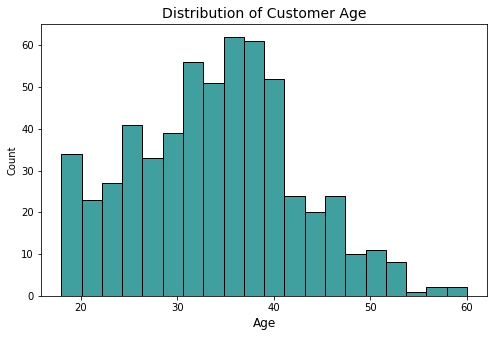

In [7]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='age', bins=20, kde=False, color='teal')

plt.title('Distribution of Customer Age', fontsize=14)
plt.xlabel('Age', fontsize=12)

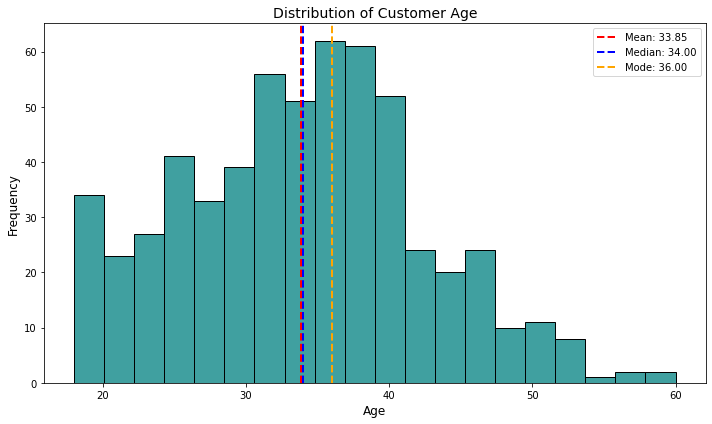

Mean age: 33.85
Median age: 34.00
Mode age: 36.00


In [8]:


# Calculate mean, median and mode
mean_age = df['age'].mean()
median_age = df['age'].median()
mode_age = df['age'].mode()[0]

# Create histogram
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='age',
    bins=20,
    kde=False,
    color='teal'
)

# Highlight mean, median and mode
plt.axvline(mean_age, color='red', linestyle='--',
            linewidth=2, label=f'Mean: {mean_age:.2f}')

plt.axvline(median_age, color='blue', linestyle='--',
            linewidth=2, label=f'Median: {median_age:.2f}')

plt.axvline(mode_age, color='orange', linestyle='--',
            linewidth=2, label=f'Mode: {mode_age:.2f}')

# Add titles and labels
plt.title('Distribution of Customer Age', fontsize=14)
plt.xlabel('Age', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

plt.legend()
plt.tight_layout()
plt.show()

# Print the values
print(f'Mean age: {mean_age:.2f}')
print(f'Median age: {median_age:.2f}')
print(f'Mode age: {mode_age:.2f}')


In [9]:
print('mean',df.age.mean())
print('mode',df.age.mode())
print('median',df.age.median())

mean 33.85370051635112
mode 0    36.0
Name: age, dtype: float64
median 34.0


In [10]:
df1=df
df1.head(2)

,customer_id,pincode,age,gender,city,membership_tier,device,annual_income_inr,monthly_spend_inr,orders_per_year,days_since_last_order,satisfaction_score,country,is_test_account,churned,monthly_spend_usd
0,100141,110001,38.0,M,Bhubaneswar,Gold,Tablet,694508.70,3191.82,12,6,7.0,India,0,No,38.47
1,100337,768001,28.0,F,Pune,Platinum,Mobile,212569.55,1044.43,11,63,1.0,India,0,Yes,12.59


In [11]:
# 1. Fill null values in the 'age' column of df1 with the median
df1['age'] = df1['age'].fillna(df1['age'].median())
df1.age.isnull().sum()

0

In [12]:
#converting age float to int
df1['age']=df.age.astype('int64')
df.age.info()

<class 'pandas.core.series.Series'>
RangeIndex: 618 entries, 0 to 617
Series name: age
Non-Null Count  Dtype
--------------  -----
618 non-null    int64
dtypes: int64(1)
memory usage: 5.0 KB


In [13]:
# df1.info()

In [14]:
per_null(df1)

customer_id              0.000000
pincode                  0.000000
age                      0.000000
gender                   5.460751
city                     0.000000
membership_tier          0.000000
device                   4.215852
annual_income_inr        7.478261
monthly_spend_inr        0.000000
orders_per_year          0.000000
days_since_last_order    0.000000
satisfaction_score       5.102041
country                  0.000000
is_test_account          0.000000
churned                  0.000000
monthly_spend_usd        0.000000
dtype: float64

In [15]:
# a funtion to give a columns details
def for_null(data,col):
    data_col_mean=data[col].mean()
    data_col_mode=data[col].mode()
    data_col_median=data[col].median()
    
    return {'mean':data_col_mean,'mode':data_col_mode,'median':data_col_median}

In [16]:
for_null(df1,'age')

{'mean': 33.862459546925564,
 'mode': 0    34
 Name: age, dtype: int64,
 'median': 34.0}

In [17]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 618 entries, 0 to 617
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   customer_id            618 non-null    int64  
 1   pincode                618 non-null    int64  
 2   age                    618 non-null    int64  
 3   gender                 586 non-null    object 
 4   city                   618 non-null    object 
 5   membership_tier        618 non-null    object 
 6   device                 593 non-null    object 
 7   annual_income_inr      575 non-null    float64
 8   monthly_spend_inr      618 non-null    float64
 9   orders_per_year        618 non-null    int64  
 10  days_since_last_order  618 non-null    int64  
 11  satisfaction_score     588 non-null    float64
 12  country                618 non-null    object 
 13  is_test_account        618 non-null    int64  
 14  churned                618 non-null    object 
 15  monthl

In [18]:
df1[['customer_id','pincode']]=df1[['customer_id','pincode']].astype('object')
df1[['customer_id','pincode']].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 618 entries, 0 to 617
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   customer_id  618 non-null    object
 1   pincode      618 non-null    object
dtypes: object(2)
memory usage: 9.8+ KB


# Gender

Text(0.5, 0, 'Gender')

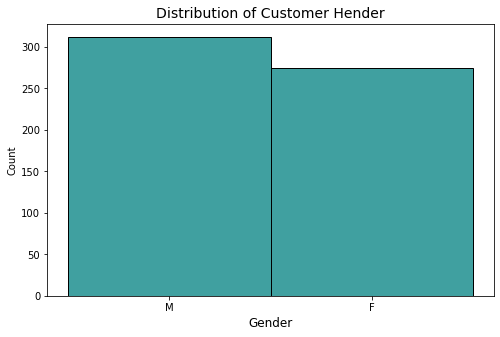

In [19]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='gender', bins=20, kde=False, color='teal')

plt.title('Distribution of Customer Hender', fontsize=14)
plt.xlabel('Gender', fontsize=12)

In [20]:
per_null(df.gender)

5.460750853242321

In [21]:
# df1.columns
print(df1.gender.value_counts())
print(df1.gender.count())

gender
M    312
F    274
Name: count, dtype: int64
586


In [22]:
# from sklearn.impute import SimpleImputer 
# import numpy as np

# # Use 'most_frequent' instead of 'mode'
# mode_imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')

# # Fit and transform the column, then convert it back to a pandas Series
# df1['gender'] = mode_imputer.fit_transform(df1[['gender']])

df1['gender'] = df1['gender'].fillna(df1['gender'].mode()[0])
df1.gender.info()

<class 'pandas.core.series.Series'>
RangeIndex: 618 entries, 0 to 617
Series name: gender
Non-Null Count  Dtype 
--------------  ----- 
618 non-null    object
dtypes: object(1)
memory usage: 5.0+ KB


In [23]:
per_null(df1.gender)

0.0

In [24]:
# 4% null in device column
print(df1.device.count())
per_null(df1.device)

593


4.215851602023609

In [25]:
df1.device.info()
df1.device.value_counts()

<class 'pandas.core.series.Series'>
RangeIndex: 618 entries, 0 to 617
Series name: device
Non-Null Count  Dtype 
--------------  ----- 
593 non-null    object
dtypes: object(1)
memory usage: 5.0+ KB


device
Mobile     384
Desktop    171
Tablet      38
Name: count, dtype: int64

In [26]:
df1['orders_per_year']=df1['orders_per_year'].astype('float64')

In [27]:
df1['device'] = df1['device'].fillna(df1['device'].mode()[0])
df1.info()
df1.device.count()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 618 entries, 0 to 617
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   customer_id            618 non-null    object 
 1   pincode                618 non-null    object 
 2   age                    618 non-null    int64  
 3   gender                 618 non-null    object 
 4   city                   618 non-null    object 
 5   membership_tier        618 non-null    object 
 6   device                 618 non-null    object 
 7   annual_income_inr      575 non-null    float64
 8   monthly_spend_inr      618 non-null    float64
 9   orders_per_year        618 non-null    float64
 10  days_since_last_order  618 non-null    int64  
 11  satisfaction_score     588 non-null    float64
 12  country                618 non-null    object 
 13  is_test_account        618 non-null    int64  
 14  churned                618 non-null    object 
 15  monthl

618

In [28]:
print('satisfaction_score',per_null(df1.satisfaction_score))
print('annual_income_inr',per_null(df1.annual_income_inr))

satisfaction_score 5.1020408163265305
annual_income_inr 7.478260869565218


In [29]:
df1[['satisfaction_score','annual_income_inr']].dtypes

satisfaction_score    float64
annual_income_inr     float64
dtype: object

In [30]:
df1.satisfaction_score.head(2)

0    7.0
1    1.0
Name: satisfaction_score, dtype: float64

In [31]:
for_null(df1,'satisfaction_score')

{'mean': 5.58843537414966,
 'mode': 0    3.0
 Name: satisfaction_score, dtype: float64,
 'median': 6.0}

In [32]:
print('mean',df1.satisfaction_score.mean(),'\n mode',df1.satisfaction_score.mode(),'\n median',df1.satisfaction_score.median())

mean 5.58843537414966 
 mode 0    3.0
Name: satisfaction_score, dtype: float64 
 median 6.0


In [33]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 618 entries, 0 to 617
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   customer_id            618 non-null    object 
 1   pincode                618 non-null    object 
 2   age                    618 non-null    int64  
 3   gender                 618 non-null    object 
 4   city                   618 non-null    object 
 5   membership_tier        618 non-null    object 
 6   device                 618 non-null    object 
 7   annual_income_inr      575 non-null    float64
 8   monthly_spend_inr      618 non-null    float64
 9   orders_per_year        618 non-null    float64
 10  days_since_last_order  618 non-null    int64  
 11  satisfaction_score     588 non-null    float64
 12  country                618 non-null    object 
 13  is_test_account        618 non-null    int64  
 14  churned                618 non-null    object 
 15  monthl

# Variance

In [34]:
# df1.var(numeric_only=True)<1

In [35]:
print('satisfaction_score',per_null(df1.satisfaction_score))
print('annual_income_inr',per_null(df1.annual_income_inr))
print('min',df1.satisfaction_score.min())
print('min',df1.satisfaction_score.max())

satisfaction_score 5.1020408163265305
annual_income_inr 7.478260869565218
min 1.0
min 10.0


In [36]:
df1['satisfaction_score']=df1.satisfaction_score.fillna(df1.satisfaction_score.mean())
df1['satisfaction_score']=df1.satisfaction_score.astype('int64')
df1.satisfaction_score.info()

<class 'pandas.core.series.Series'>
RangeIndex: 618 entries, 0 to 617
Series name: satisfaction_score
Non-Null Count  Dtype
--------------  -----
618 non-null    int64
dtypes: int64(1)
memory usage: 5.0 KB


In [37]:
df1['satisfaction_score']=df1.satisfaction_score.fillna(df1.satisfaction_score.mean())
df1['satisfaction_score']=df1.satisfaction_score.astype('int64')
df1.satisfaction_score.info()

<class 'pandas.core.series.Series'>
RangeIndex: 618 entries, 0 to 617
Series name: satisfaction_score
Non-Null Count  Dtype
--------------  -----
618 non-null    int64
dtypes: int64(1)
memory usage: 5.0 KB


In [38]:
# per_null(df1.annual_income_inr)

In [39]:
# for_null(df1,'annual_income_inr')
print('mean',df1.annual_income_inr.mean())
print('median',df1.annual_income_inr.median())
print('min',df1.annual_income_inr.min())
print('max',df1.annual_income_inr.max())

mean 498538.5573769584
median 408005.74
min 53818.52
max 5391480.167521113


In [40]:
# plt.figure(figsize=(8, 5))

# sns.histplot(data=df, x='satisfaction_score', bins=20, kde=False, color='teal')

# plt.title('Distribution of satisfaction_score', fontsize=14)
# plt.xlabel('satisfaction_score', fontsize=12)

Text(0.5, 0, 'annual_income_inr')

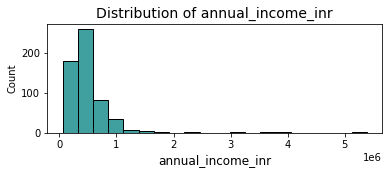

In [41]:
plt.figure(figsize=(6, 2))

sns.histplot(data=df, x='annual_income_inr', bins=20, kde=False, color='teal')

plt.title('Distribution of annual_income_inr', fontsize=14)
plt.xlabel('annual_income_inr', fontsize=12)

 ### Median is Better for This ColumnPresence
 
 of Extreme Outliers (Skewness):Notice how large the maximum value ($5,391,480$) is compared to the median ($408,005$). The max is over 13 times higher than the median!This huge gap indicates that your income data is right-skewed (a small number of customers have extremely high incomes, pulling the average/mean upward).The mean is heavily sensitive to outliers—a few massive values will artificially inflate it, making it higher than what a "typical" customer earns. The median (the middle value) is completely immune to these extreme spikes.

In [42]:
df1['annual_income_inr']=df1.annual_income_inr.fillna(df1.annual_income_inr.median())
df1['annual_income_inr']=df1.annual_income_inr.astype('int64')
df1.annual_income_inr.info()

<class 'pandas.core.series.Series'>
RangeIndex: 618 entries, 0 to 617
Series name: annual_income_inr
Non-Null Count  Dtype
--------------  -----
618 non-null    int64
dtypes: int64(1)
memory usage: 5.0 KB


In [43]:
df1.isnull().sum()

customer_id              0
pincode                  0
age                      0
gender                   0
city                     0
membership_tier          0
device                   0
annual_income_inr        0
monthly_spend_inr        0
orders_per_year          0
days_since_last_order    0
satisfaction_score       0
country                  0
is_test_account          0
churned                  0
monthly_spend_usd        0
dtype: int64

In [44]:
df1.orders_per_year.info()

<class 'pandas.core.series.Series'>
RangeIndex: 618 entries, 0 to 617
Series name: orders_per_year
Non-Null Count  Dtype  
--------------  -----  
618 non-null    float64
dtypes: float64(1)
memory usage: 5.0 KB


In [45]:
# df1.city.value_counts()
# df1.membership_tier.value_counts()
# Convert to category
df1['city'] = df1['city'].astype('category')
df1['membership_tier'] = df1['membership_tier'].astype('category')

In [46]:
# # Check memory usage before and after comparison
# print("--- Memory Usage Before (df) ---")
# print(df.memory_usage(deep=True))
# print(f"Total Memory (df): {df.memory_usage(deep=True).sum() / 1024:.2f} KB\n")

# print("--- Memory Usage After Cell 60 (df1) ---")
# print(df1.memory_usage(deep=True))
# print(f"Total Memory (df1): {df1.memory_usage(deep=True).sum() / 1024:.2f} KB")



## 2. Zero Variance and Near-Zero Variance


**1. Compute the variance of all numeric columns. Which are below 1? Why is raw variance a misleading test here? (Hint: compare `monthly_spend_usd` with `annual_income_inr`.)

**2. Find the column with exactly one unique value using `nunique()`. Drop it.

**3. `is_test_account` is near-zero variance. Use `value_counts(normalize=True)` to show the share of the dominant value, then decide whether to drop it and justify your choice.

**4. Write a loop that flags any column where one value covers more than 99% of rows.

In [47]:
num_df1=df1.select_dtypes(include=['number'])
num_df1.head()

,age,annual_income_inr,monthly_spend_inr,orders_per_year,days_since_last_order,satisfaction_score,is_test_account,monthly_spend_usd
0,38,694508,3191.82,12.0,6,7,0,38.47
1,28,212569,1044.43,11.0,63,1,0,12.59
2,28,244778,1300.03,5.0,8,10,0,15.66
3,29,417334,3977.12,8.0,43,3,0,47.91
4,30,1176749,7870.82,10.0,66,6,0,94.83


In [48]:
num_df1.var()<1

age                      False
annual_income_inr        False
monthly_spend_inr        False
orders_per_year          False
days_since_last_order    False
satisfaction_score       False
is_test_account           True
monthly_spend_usd        False
dtype: bool

In [49]:
num_df1.nunique()

age                       40
annual_income_inr        558
monthly_spend_inr        600
orders_per_year           18
days_since_last_order    105
satisfaction_score        10
is_test_account            2
monthly_spend_usd        576
dtype: int64

In [77]:
# Finding whether any numeric column has exactly one unique value.
num_df1.nunique()==1

age                      False
annual_income_inr        False
monthly_spend_inr        False
orders_per_year          False
days_since_last_order    False
satisfaction_score       False
is_test_account          False
monthly_spend_usd        False
dtype: bool

In [78]:
num_df1.nunique()==2

age                      False
annual_income_inr        False
monthly_spend_inr        False
orders_per_year          False
days_since_last_order    False
satisfaction_score       False
is_test_account           True
monthly_spend_usd        False
dtype: bool

In [55]:
# num_df1.annual_income_inr.nunique()
#2. Find the column with exactly one unique value using `nunique()`. Drop it.
# df1.country.nunique() #[df1.nunique() == 1]
# select column based on single constant value 

# df1.columns[df1.nunique() == 1]

# constant_cols = df1.columns[df1.nunique() == 1]

# df1.drop(columns=constant_cols, inplace=True)

# df1.columns()

# Find columns with exactly one unique value
constant_cols = df1.columns[df1.nunique() == 1]

print(constant_cols)

Index(['country'], dtype='object')


In [59]:
# df1.drop(columns=constant_cols, inplace=True)

In [60]:
df1.columns

Index(['customer_id', 'pincode', 'age', 'gender', 'city', 'membership_tier',
       'device', 'annual_income_inr', 'monthly_spend_inr', 'orders_per_year',
       'days_since_last_order', 'satisfaction_score', 'is_test_account',
       'churned', 'monthly_spend_usd'],
      dtype='object')

In [52]:
# df1.country.value_counts()
print(df1.is_test_account.nunique())
print(df1.is_test_account.value_counts())
print('variantion',df1.is_test_account.var())

2
is_test_account
0    617
1      1
Name: count, dtype: int64
variantion 0.0016181229773462777


In [75]:
(617/df1.is_test_account.count())*100
# so 99.83% of data is 0 in this data set so its near zero variance

99.83818770226537

### 4. Write a loop that flags any column where one value covers more than 99% of rows.


In [86]:
def loop(data):
    for col in data.columns:
        # Calculate the proportion of each unique value
        proportions = data[col].value_counts(normalize=True)

        # Check if the largest proportion exceeds 99%
        if proportions.max() > 0.99:
            print(f"{col} has one value covering more than 99% of rows")

loop(df1)

is_test_account has one value covering more than 99% of rows


In [89]:
# converting into percetile
df1.is_test_account.value_counts(normalize=True)

is_test_account
0    0.998382
1    0.001618
Name: proportion, dtype: float64

# 3. Duplicate Records

# df = scaler.fit_transform(data)

What it means in plain English:
scaler (The Measuring Tool):
Imagine you have a box of data (numbers) with completely different scales—for example, one column is house prices in hundreds of thousands, and another is the number of bedrooms (1 to 5). Machine learning models get confused when numbers are on such different scales. The scaler is a tool designed to fix this by squishing/stretching all your numbers onto a standard, equal playing field (usually between 0 and 1, or around a mean of 0).

fit (Learn the Rules):
The fit part looks at all the numbers in your dataset, calculates the minimum, maximum, or average values, and figures out the formula needed to scale them. (For example: "Ah, the lowest number here is 10 and the highest is 100, so I need to map them accordingly.")

transform (Apply the Changes):
The transform part actually does the math on every single number in your dataset, converting them using the rules it just learned.

fit_transform (Do Both at Once):
Instead of writing two separate lines—one to learn the rules (fit) and another to apply them (transform)—combining them into fit_transform tells Python: "Look at this data, figure out its min/max/average, and convert it all in one smooth step."

df = ... (Save the Result):
Finally, it takes your newly standardized numbers and saves them back into your dataset (df).